**Name** - Harshal Manohar Mekhe<br>
**PRN** - 202401040051<br>
**Roll** - 14<br>
**Subject** - AIML

# Loan Approval Prediction Using Ensemble Learning Techniques

**Assignment:** Implement Stacking, AdaBoost, and Voting ensemble classifiers for loan approval prediction, then compare them with individual machine learning classifiers.

## Problem Statement

Develop and implement ensemble learning techniques to predict whether a loan application should be approved or rejected based on applicant attributes such as income, credit history, loan amount, employment status, and other relevant factors.

The study involves implementing three ensemble techniques: Stacking, AdaBoost, and Voting Classifiers by combining suitable base machine learning algorithms. The performance of these ensemble models will be compared with individual classification algorithms using accuracy, precision, recall, F1-score, and log loss. The objective is to investigate whether ensemble learning improves prediction performance and determine the suitability of each ensemble technique for loan approval prediction.

## Objectives

1. Understand and preprocess the loan approval dataset.
2. Train individual base classifiers: SVM, Decision Tree, KNN, and Naïve Bayes.
3. Implement a Stacking ensemble with a Logistic Regression meta-classifier.
4. Implement AdaBoost using a decision stump as its weak learner.
5. Implement hard and soft Voting ensembles.
6. Compare all models using appropriate classification metrics.
7. Discuss findings, limitations, and possible improvements.

**Dataset:** [Loan Prediction Dataset on Kaggle](https://www.kaggle.com/datasets/altruistdelhite04/loan-prediction-problem-dataset).


## 1. Theoretical Background

### 1.1 What is Ensemble Learning?

Ensemble learning is a machine learning approach in which multiple models, called **base learners**, are combined to produce a final prediction. The central idea is that a suitable combination of models may be more reliable or accurate than relying on a single model.

Ensemble methods can reduce variance, improve predictive performance, or combine different types of decision boundaries. However, an ensemble is not guaranteed to outperform every individual classifier; its performance must be tested on unseen data.

### 1.2 Stacking Ensemble

**Stacking (stacked generalization)** combines predictions from multiple base classifiers using another model called a **meta-classifier**.

The process has two main levels:

1. **Level 0 – Base learners:** Several models are trained, such as SVM, Decision Tree, KNN, and Naïve Bayes.
2. **Level 1 – Meta-classifier:** A second model, such as Logistic Regression, learns from the base models' predictions and produces the final prediction.

To avoid data leakage, the meta-classifier is trained using out-of-fold predictions. In cross-validation, each base learner predicts observations that were not used to fit that fold's model. The meta-classifier then learns how to combine these predictions.

**Advantages:**
- Combines different learning approaches.
- Can learn which base-model predictions are useful.
- May improve predictive performance when base models make complementary errors.

**Limitations:**
- More computationally expensive than a single model.
- More complex to interpret and tune.
- Can overfit if the stacking procedure is not designed carefully.

**In this assignment:** SVM, Decision Tree, KNN, and Gaussian Naïve Bayes are used as base learners, while Logistic Regression is used as the meta-classifier.

### 1.3 AdaBoost Ensemble

**AdaBoost (Adaptive Boosting)** is a boosting technique that combines several weak learners to create a stronger classifier. It trains learners sequentially, giving greater attention to observations that earlier learners classified incorrectly.

Initially, training observations receive equal weights. After each learner is trained, the weights of misclassified observations are increased so that the next learner focuses more on difficult examples. The final prediction is a weighted combination of the learners' predictions.

A **decision stump** is a Decision Tree with a maximum depth of one. It is a common simple weak learner for AdaBoost.

**Advantages:**
- Can turn simple weak learners into a stronger combined model.
- Focuses successive learners on difficult observations.
- Often works well with shallow decision trees.

**Limitations:**
- Can be sensitive to noisy observations and outliers.
- Sequential training can take longer than training a single learner.
- Performance depends on the number of estimators and learning rate.

**In this assignment:** AdaBoost uses a decision stump (`DecisionTreeClassifier(max_depth=1)`) as its base estimator.

### 1.4 Voting Ensemble

A **Voting Classifier** combines predictions from multiple independently trained classifiers.

There are two common approaches:

- **Hard Voting:** Each classifier casts a vote for a class. The class receiving the most votes becomes the final prediction.
- **Soft Voting:** The predicted class probabilities from all classifiers are averaged, and the class with the highest average probability is selected.

Soft voting uses probability estimates, so it is most appropriate when the component classifiers provide reasonably calibrated probabilities.

**Advantages:**
- Simple way to combine different classifiers.
- Easy to implement and compare.
- Can reduce dependence on the weaknesses of one individual model.

**Limitations:**
- Hard voting treats each classifier's vote equally.
- Soft voting can be affected by poorly calibrated probabilities.
- Adding weak or highly correlated models may not improve performance.

**In this assignment:** The same four base classifiers are combined using both hard voting and soft voting.

### 1.5 Base Classifiers Used

The ensemble models use the following base algorithms:

| Algorithm | Main idea |
|---|---|
| SVM | Finds a separating boundary with a large margin |
| Decision Tree | Makes predictions using feature-based decision rules |
| KNN | Predicts from the classes of nearby training observations |
| Gaussian Naïve Bayes | Uses Bayes' theorem with a Gaussian feature-distribution assumption |

### 1.6 Summary of Ensemble Methods

| Method | How models are combined | Training style |
|---|---|---|
| Stacking | Meta-classifier learns from base-model predictions | Base learners plus a second-level learner |
| AdaBoost | Weighted combination of sequential weak learners | Sequential |
| Hard Voting | Majority vote across predicted classes | Base learners trained independently |
| Soft Voting | Average of predicted class probabilities | Base learners trained independently |

The best method depends on the dataset, base learners, model settings, and the cost of different prediction errors.


## 2. Evaluation Metrics

The models are evaluated on the same held-out test set. In this notebook, **Approved (1)** is treated as the positive class.

### 2.1 Confusion Matrix

A confusion matrix compares actual and predicted classes.

| Term | Meaning |
|---|---|
| True Positive (TP) | Actually approved and predicted approved |
| True Negative (TN) | Actually rejected and predicted rejected |
| False Positive (FP) | Actually rejected but predicted approved |
| False Negative (FN) | Actually approved but predicted rejected |

### 2.2 Accuracy

The proportion of all predictions that are correct.

\[
Accuracy = \frac{TP + TN}{TP + TN + FP + FN}
\]

Higher is generally better, but accuracy can be misleading when classes are imbalanced.

### 2.3 Precision

The proportion of predicted approvals that were actually approved.

\[
Precision = \frac{TP}{TP + FP}
\]

Higher precision means fewer rejected applications are incorrectly labelled as approved.

### 2.4 Recall

The proportion of actually approved applications that the model correctly identifies.

\[
Recall = \frac{TP}{TP + FN}
\]

Higher recall means fewer actually approved applications are incorrectly labelled as rejected.

### 2.5 F1-Score

The harmonic mean of precision and recall.

\[
F1 = 2 \times \frac{Precision \times Recall}{Precision + Recall}
\]

It is useful when both precision and recall matter.

### 2.6 Log Loss

Log loss (binary cross-entropy) evaluates the quality of predicted probabilities. It penalizes confident predictions when they are wrong.

\[
LogLoss = -\frac{1}{N}\sum_{i=1}^{N}
[y_i\log(p_i)+(1-y_i)\log(1-p_i)]
\]

Here, \(N\) is the number of test records, \(y_i\) is the actual class, and \(p_i\) is the predicted probability of approval. **Lower log loss is better.**

### 2.7 Metric Summary

| Metric | Measures | Preferred result |
|---|---|---|
| Accuracy | Overall correctness | Higher |
| Precision | Correctness of predicted approvals | Higher |
| Recall | Coverage of actual approvals | Higher |
| F1-score | Balance of precision and recall | Higher |
| Log loss | Quality of predicted probabilities | Lower |

Loan approval errors can have different consequences. Therefore, model selection should consider more than accuracy alone.


## 3. Import Required Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import (
    StackingClassifier,
    AdaBoostClassifier,
    VotingClassifier
)

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    log_loss, classification_report, confusion_matrix
)

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
print("Libraries imported successfully.")

Libraries imported successfully.


## 4. Load the Dataset
Download `train.csv` from the Kaggle dataset linked above. Run this cell and upload the CSV file.

In [3]:
from google.colab import files

uploaded = files.upload()
csv_files = [name for name in uploaded.keys() if name.lower().endswith(".csv")]

if not csv_files:
    raise ValueError("Please upload the train.csv dataset.")

df = pd.read_csv(csv_files[0])
print("Loaded file:", csv_files[0])
display(df.head())

Saving train_u6lujuX_CVtuZ9i.csv to train_u6lujuX_CVtuZ9i.csv
Loaded file: train_u6lujuX_CVtuZ9i.csv


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


## 5. Understand the Dataset

In [4]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nStatistical summary:")
display(df.describe(include="all").T)

Dataset shape: (614, 13)

Column names:
['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Pro

,Missing Values
Loan_ID,0
Gender,13
Married,3
Dependents,15
Education,0
Self_Employed,32
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,22
Loan_Amount_Term,14



Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Loan_ID,614,614,LP001002,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,601,2,Male,489,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Married,611,2,Yes,398,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,599,4,0,345,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Education,614,2,Graduate,480,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Self_Employed,582,2,No,500,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ApplicantIncome,614.0,NaN,NaN,NaN,5403.459283,6109.041673,150.0,2877.5,3812.5,5795.0,81000.0
CoapplicantIncome,614.0,NaN,NaN,NaN,1621.245798,2926.248369,0.0,0.0,1188.5,2297.25,41667.0
LoanAmount,592.0,NaN,NaN,NaN,146.412162,85.587325,9.0,100.0,128.0,168.0,700.0
Loan_Amount_Term,600.0,NaN,NaN,NaN,342.0,65.12041,12.0,360.0,360.0,360.0,480.0


## 6. Exploratory Data Analysis (EDA)

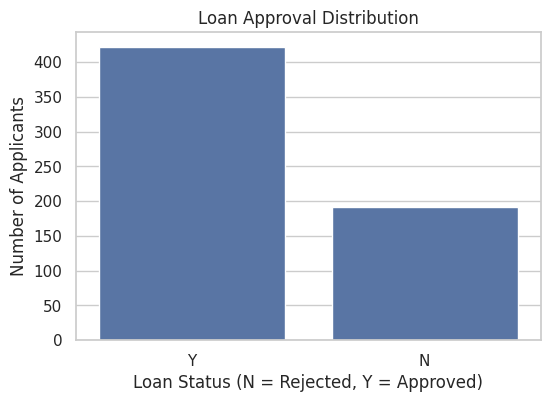

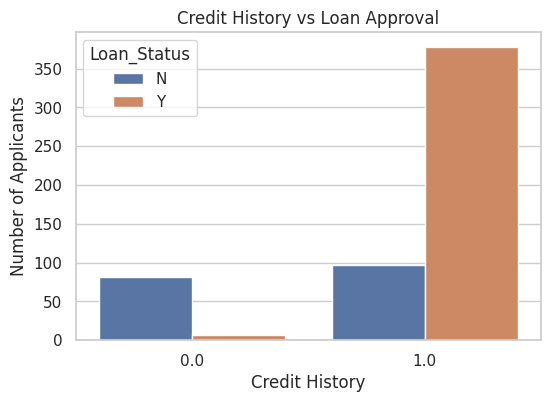

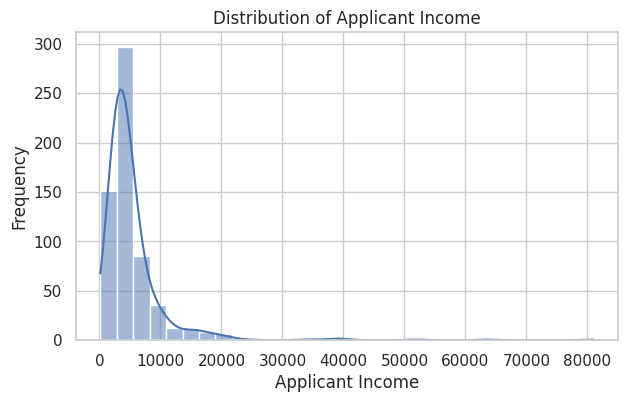

In [5]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Loan_Status")
plt.title("Loan Approval Distribution")
plt.xlabel("Loan Status (N = Rejected, Y = Approved)")
plt.ylabel("Number of Applicants")
plt.show()

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Credit_History", hue="Loan_Status")
plt.title("Credit History vs Loan Approval")
plt.xlabel("Credit History")
plt.ylabel("Number of Applicants")
plt.show()

plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="ApplicantIncome", bins=30, kde=True)
plt.title("Distribution of Applicant Income")
plt.xlabel("Applicant Income")
plt.ylabel("Frequency")
plt.show()

## 7. Data Preprocessing

The `Loan_ID` column is an identifier and is removed. The target variable is mapped to numbers (`N` = 0, `Y` = 1). Numerical missing values are filled with the median, and categorical missing values are filled with the most frequent category. Categorical columns are one-hot encoded and numerical columns are standardized.

Preprocessing is placed inside scikit-learn pipelines. This ensures that the imputer, encoder, and scaler are fitted on training data during model fitting rather than on the full dataset, helping prevent data leakage.


In [6]:
data = df.drop(columns=["Loan_ID"], errors="ignore").copy()
data = data.dropna(subset=["Loan_Status"])

X = data.drop(columns=["Loan_Status"])
y = data["Loan_Status"].map({"N": 0, "Y": 1})

valid_rows = y.notna()
X = X.loc[valid_rows]
y = y.loc[valid_rows].astype(int)

numerical_cols = X.select_dtypes(include=["number"]).columns.tolist()
categorical_cols = X.select_dtypes(exclude=["number"]).columns.tolist()

print("Numerical columns:", numerical_cols)
print("Categorical columns:", categorical_cols)
print("\nTarget distribution (0 = Rejected, 1 = Approved):")
display(y.value_counts().sort_index())

Numerical columns: ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History']
Categorical columns: ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Property_Area']

Target distribution (0 = Rejected, 1 = Approved):


,count
Loan_Status,
0,192
1,422


In [7]:
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numerical_transformer, numerical_cols),
    ("cat", categorical_transformer, categorical_cols)
])

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


## 8. Train-Test Split
The dataset is divided into 80% training data and 20% testing data. Stratification maintains approximately the same target-class proportions in both sets.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

print("\nTraining class proportions:")
display(y_train.value_counts(normalize=True).rename("Proportion"))

print("\nTesting class proportions:")
display(y_test.value_counts(normalize=True).rename("Proportion"))

Training records: 491
Testing records: 123

Training class proportions:


,Proportion
Loan_Status,
1,0.686354
0,0.313646



Testing class proportions:


,Proportion
Loan_Status,
1,0.691057
0,0.308943


## 9. Train the Base Classification Models

First, train the four individual classifiers. Their results will act as the baseline for comparison with the ensemble models.


In [9]:
base_models = {
    "SVM": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", SVC(kernel="linear", probability=True, random_state=42))
    ]),
    "Decision Tree": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(max_depth=5, random_state=42))
    ]),
    "KNN": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", KNeighborsClassifier(n_neighbors=5))
    ]),
    "Naive Bayes": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", GaussianNB())
    ])
}

for name, model in base_models.items():
    model.fit(X_train, y_train)
    print(f"{name} trained successfully.")

SVM trained successfully.
Decision Tree trained successfully.
KNN trained successfully.
Naive Bayes trained successfully.


## 10. Implement Stacking Ensemble

Stacking trains multiple base classifiers and uses a meta-classifier to learn how to combine their predictions. `StackingClassifier` generates out-of-fold predictions for training its final estimator, which helps avoid training the meta-classifier on in-sample base-model predictions.

Here, Logistic Regression is the meta-classifier. The preprocessing pipeline is applied before the stacking classifier.


In [10]:
# Base estimators operate on the preprocessed feature matrix
stack_estimators = [
    ("svm", SVC(kernel="linear", probability=True, random_state=42)),
    ("tree", DecisionTreeClassifier(max_depth=5, random_state=42)),
    ("knn", KNeighborsClassifier(n_neighbors=5)),
    ("nb", GaussianNB())
]

stacking_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("ensemble", StackingClassifier(
        estimators=stack_estimators,
        final_estimator=LogisticRegression(max_iter=1000),
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
        stack_method="predict_proba"
    ))
])

stacking_model.fit(X_train, y_train)
print("Stacking ensemble trained successfully.")

Stacking ensemble trained successfully.


## 11. Implement AdaBoost Ensemble

AdaBoost trains weak learners sequentially. Each new learner gives more attention to observations that previous learners classified incorrectly.

A decision stump is a decision tree with maximum depth 1. It is used here as the weak learner. The `estimator` parameter is used by current scikit-learn versions.


In [11]:
# Decision stump: a decision tree with only one split
decision_stump = DecisionTreeClassifier(max_depth=1, random_state=42)

adaboost_classifier = AdaBoostClassifier(
    estimator=decision_stump,
    n_estimators=50,
    learning_rate=1.0,
    random_state=42
)

adaboost_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("ensemble", adaboost_classifier)
])

adaboost_model.fit(X_train, y_train)
print("AdaBoost ensemble trained successfully.")

AdaBoost ensemble trained successfully.


## 12. Implement Voting Ensemble

Voting combines the predictions of independently trained base classifiers.

- **Hard Voting:** Uses the majority class vote.
- **Soft Voting:** Averages class probabilities and selects the class with the highest average probability.

All component models used here support probability prediction, allowing soft voting.


In [12]:
voting_estimators = [
    ("svm", SVC(kernel="linear", probability=True, random_state=42)),
    ("tree", DecisionTreeClassifier(max_depth=5, random_state=42)),
    ("knn", KNeighborsClassifier(n_neighbors=5)),
    ("nb", GaussianNB())
]

hard_voting_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("ensemble", VotingClassifier(
        estimators=voting_estimators,
        voting="hard"
    ))
])

soft_voting_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("ensemble", VotingClassifier(
        estimators=voting_estimators,
        voting="soft"
    ))
])

hard_voting_model.fit(X_train, y_train)
soft_voting_model.fit(X_train, y_train)

print("Hard Voting ensemble trained successfully.")
print("Soft Voting ensemble trained successfully.")

Hard Voting ensemble trained successfully.
Soft Voting ensemble trained successfully.


## 13. Compare Base and Ensemble Models
Evaluate all models on the same test set. The positive class is Approved (1). Log loss is calculated from predicted probabilities; lower is better.

In [17]:

all_models = {
    **base_models,
    "Stacking": stacking_model,
    "AdaBoost": adaboost_model,
    "Hard Voting": hard_voting_model,
    "Soft Voting": soft_voting_model
}

results = []
predictions = {}

for name, model in all_models.items():

    print(f"Evaluating {name}...")

    # Predict class labels
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    # Calculate Log Loss only if probabilities are available
    if hasattr(model, "predict_proba") and name != "Hard Voting":

        y_prob_all = model.predict_proba(X_test)

        model_classes = list(model.classes_)

        loss = log_loss(
            y_test,
            y_prob_all,
            labels=model_classes
        )

    else:
        loss = np.nan

    # Store evaluation metrics
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, pos_label=1, zero_division=0),
        "Recall": recall_score(y_test, y_pred, pos_label=1, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, pos_label=1, zero_division=0),
        "Log Loss": loss
    })

# Display comparison table
results_df = pd.DataFrame(results).set_index("Model")

print("\nBase Models vs Ensemble Models:")
display(results_df.round(4))


Evaluating SVM...
Evaluating Decision Tree...
Evaluating KNN...
Evaluating Naive Bayes...
Evaluating Stacking...
Evaluating AdaBoost...
Evaluating Hard Voting...
Evaluating Soft Voting...

Base Models vs Ensemble Models:


,Accuracy,Precision,Recall,F1-Score,Log Loss
Model,,,,,
SVM,0.8537,0.8317,0.9882,0.9032,0.4152
Decision Tree,0.8211,0.8247,0.9412,0.8791,2.1378
KNN,0.8699,0.8485,0.9882,0.9130,1.7262
Naive Bayes,0.8455,0.8367,0.9647,0.8962,0.6822
Stacking,0.8537,0.8317,0.9882,0.9032,0.4128
AdaBoost,0.8537,0.8384,0.9765,0.9022,0.5592
Hard Voting,0.8618,0.8400,0.9882,0.9081,NaN
Soft Voting,0.8537,0.8317,0.9882,0.9032,0.4072


### Classification Reports

In [18]:
for name, y_pred in predictions.items():
    print(f"\n{name}")
    print(classification_report(
        y_test, y_pred,
        labels=[0, 1],
        target_names=["Rejected", "Approved"],
        zero_division=0
    ))


SVM
              precision    recall  f1-score   support

    Rejected       0.95      0.55      0.70        38
    Approved       0.83      0.99      0.90        85

    accuracy                           0.85       123
   macro avg       0.89      0.77      0.80       123
weighted avg       0.87      0.85      0.84       123


Decision Tree
              precision    recall  f1-score   support

    Rejected       0.81      0.55      0.66        38
    Approved       0.82      0.94      0.88        85

    accuracy                           0.82       123
   macro avg       0.82      0.75      0.77       123
weighted avg       0.82      0.82      0.81       123


KNN
              precision    recall  f1-score   support

    Rejected       0.96      0.61      0.74        38
    Approved       0.85      0.99      0.91        85

    accuracy                           0.87       123
   macro avg       0.90      0.80      0.83       123
weighted avg       0.88      0.87      0.86      

## 14. Confusion Matrices

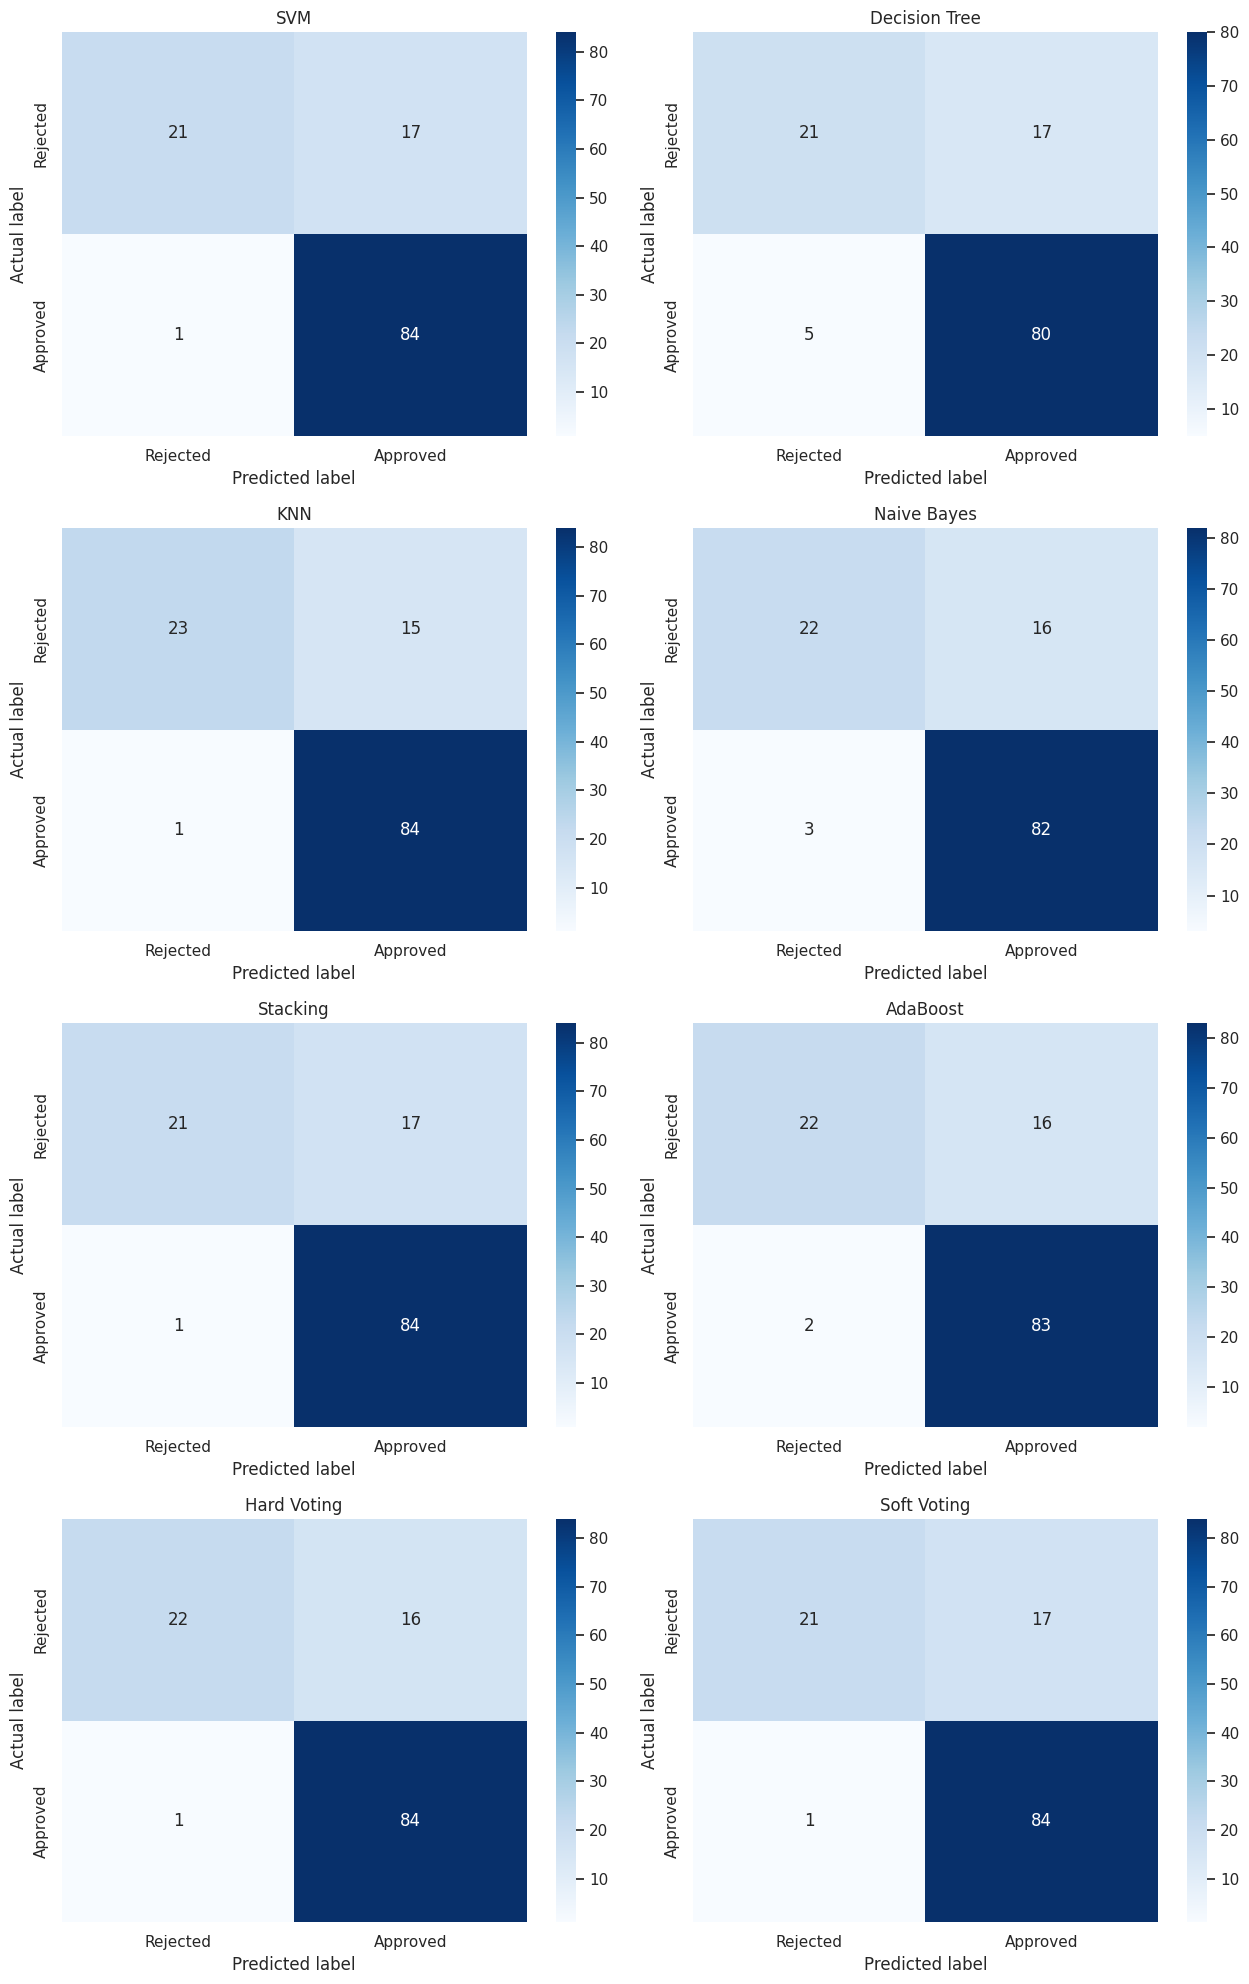

In [19]:
# Plot confusion matrices for all models
model_names = list(predictions.keys())
fig, axes = plt.subplots(4, 2, figsize=(13, 20))
axes = axes.flatten()

for ax, name in zip(axes, model_names):
    cm = confusion_matrix(y_test, predictions[name], labels=[0, 1])
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=["Rejected", "Approved"],
        yticklabels=["Rejected", "Approved"],
        ax=ax
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")

# Hide unused final subplot
for ax in axes[len(model_names):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

## 15. Performance Comparison Graphs

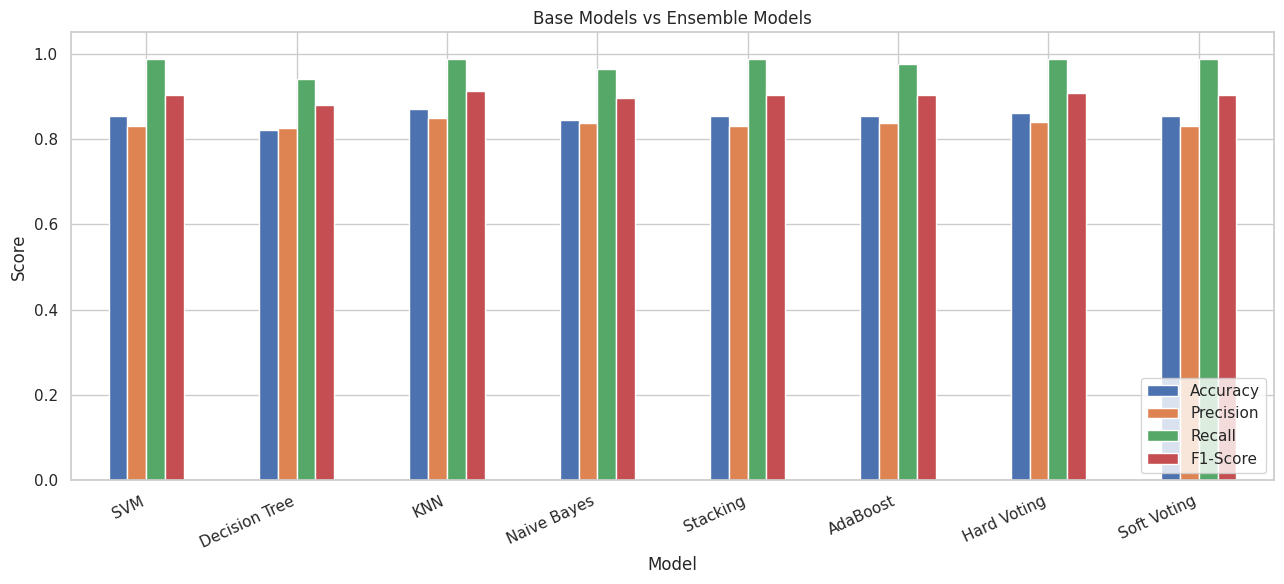

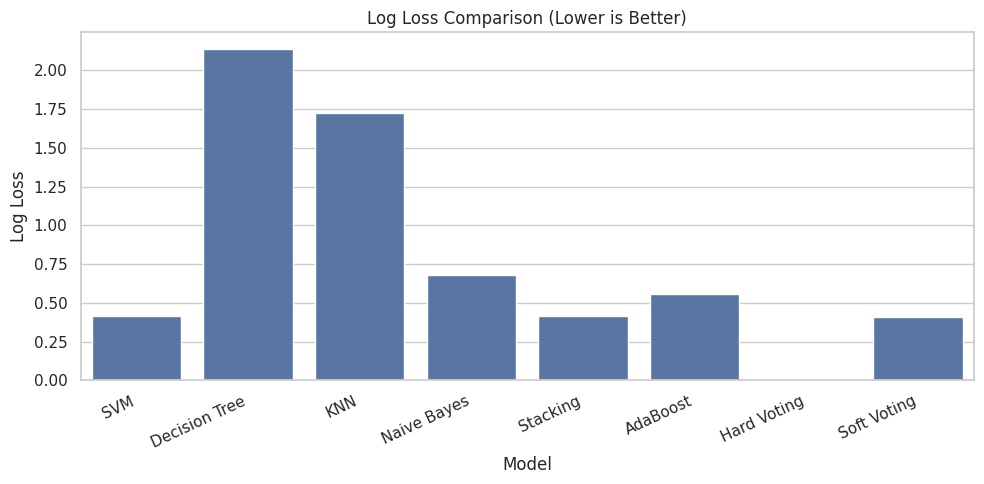

In [20]:
metric_columns = ["Accuracy", "Precision", "Recall", "F1-Score"]

results_df[metric_columns].plot(
    kind="bar", figsize=(13, 6), ylim=(0, 1.05)
)
plt.title("Base Models vs Ensemble Models")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=25, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
sns.barplot(x=results_df.index, y=results_df["Log Loss"])
plt.title("Log Loss Comparison (Lower is Better)")
plt.xlabel("Model")
plt.ylabel("Log Loss")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## 16. Identify the Best-Performing Model

The following cell identifies the model with the highest F1-score. This gives a balance between precision and recall for the approved class. It is only one possible selection criterion; the consequences of false approvals and false rejections should also be considered.


In [21]:
best_model_name = results_df["F1-Score"].idxmax()
best_model_result = results_df.loc[best_model_name]

print("Best model by F1-score:", best_model_name)
print("Accuracy :", round(best_model_result["Accuracy"], 4))
print("Precision:", round(best_model_result["Precision"], 4))
print("Recall   :", round(best_model_result["Recall"], 4))
print("F1-score :", round(best_model_result["F1-Score"], 4))
print("Log loss :", round(best_model_result["Log Loss"], 4))

Best model by F1-score: KNN
Accuracy : 0.8699
Precision: 0.8485
Recall   : 0.9882
F1-score : 0.913
Log loss : 1.7262


## 17. Findings and Discussion

Use the actual results from the comparison table and graphs to complete this discussion. Do not assume that an ensemble will always outperform an individual classifier.

### When to use each ensemble method

- **Stacking:** Consider it when different base classifiers make complementary errors and there is enough data to train a reliable meta-classifier. It can combine diverse models, but it adds complexity and computational cost.
- **AdaBoost:** Consider it when relatively simple weak learners can be combined to improve performance. It may be sensitive to noisy observations and outliers.
- **Hard Voting:** Consider it when a simple majority decision is desired and model probabilities are not trusted or are unavailable.
- **Soft Voting:** Consider it when classifiers provide useful probability estimates. It uses confidence information, but probability calibration can affect results.

### Questions to answer using your results

1. Did any ensemble model outperform the best individual classifier?
2. Which model achieved the highest F1-score?
3. Which model achieved the lowest log loss?
4. Did hard voting and soft voting produce different results?
5. Did Stacking improve the result compared with its base classifiers?
6. Which error is more important in the application context: false approval or false rejection?

### Potential areas for further research or improvement

- Tune hyperparameters using cross-validation and grid or randomized search.
- Try other base learners and meta-classifiers.
- Test different AdaBoost learning rates and numbers of estimators.
- Calibrate predicted probabilities before using soft voting.
- Evaluate class imbalance using class weights or resampling within cross-validation.
- Use additional evaluation metrics such as ROC-AUC, PR-AUC, and balanced accuracy.
- Test the final models on a separate external dataset.
- Examine fairness, explainability, and the impact of prediction errors across applicant groups.


## 18. Conclusion

In [22]:
# Create a conclusion using the actual measured results
best_f1_model = results_df["F1-Score"].idxmax()
lowest_loss_model = results_df["Log Loss"].idxmin()

print(
    f"The models were compared on the same held-out test set. "
    f"{best_f1_model} achieved the highest F1-score "
    f"({results_df.loc[best_f1_model, 'F1-Score']:.3f}), while "
    f"{lowest_loss_model} achieved the lowest log loss "
    f"({results_df.loc[lowest_loss_model, 'Log Loss']:.3f}). "
    "These results show how individual classifiers and ensemble methods "
    "can differ in their predictive performance. The most suitable model "
    "should be selected by considering precision, recall, F1-score, "
    "probability quality, and the consequences of incorrect decisions."
)

The models were compared on the same held-out test set. KNN achieved the highest F1-score (0.913), while Soft Voting achieved the lowest log loss (0.407). These results show how individual classifiers and ensemble methods can differ in their predictive performance. The most suitable model should be selected by considering precision, recall, F1-score, probability quality, and the consequences of incorrect decisions.


## 19. Assignment Summary

In this assignment, individual classification algorithms and ensemble learning techniques were implemented for loan approval prediction. SVM, Decision Tree, KNN, and Naïve Bayes were used as base classifiers. Stacking combined base-model predictions through a Logistic Regression meta-classifier, AdaBoost combined sequential weak learners, and Voting combined predictions using hard and soft voting.

All models were evaluated on the same test data using accuracy, precision, recall, F1-score, and log loss. Confusion matrices and comparison graphs were used to study their performance. The results provide a practical comparison of individual and ensemble classifiers and demonstrate that the most suitable approach depends on the dataset and the costs of different prediction errors.

**Note:** This notebook is for educational purposes. Predictions from this dataset should not be used to make real lending or credit decisions without extensive validation, fairness assessment, explainability, and appropriate human oversight.
